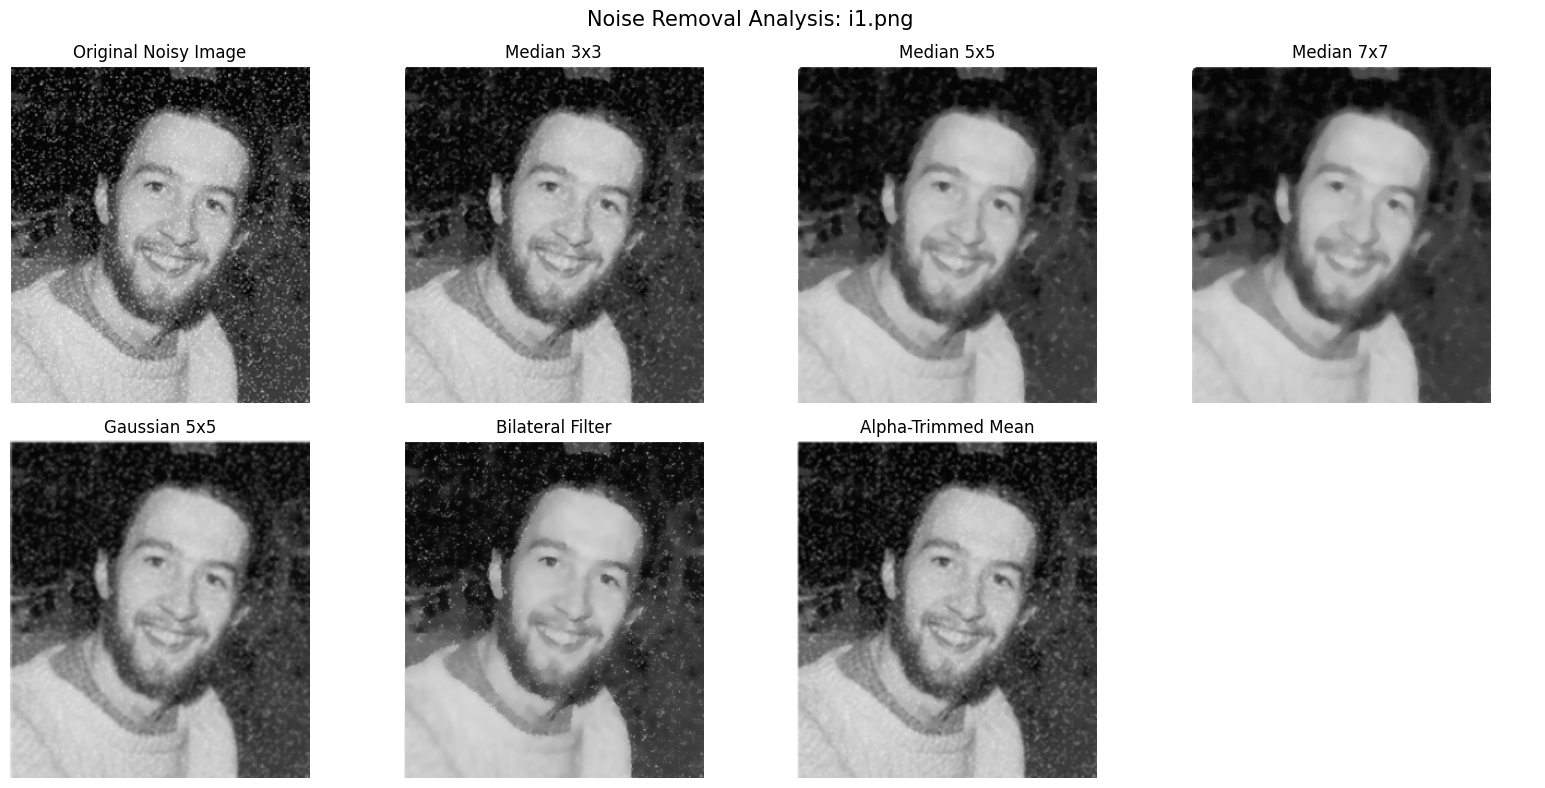

Processed image: i1.png
Results saved in: OPE7_Results\i1


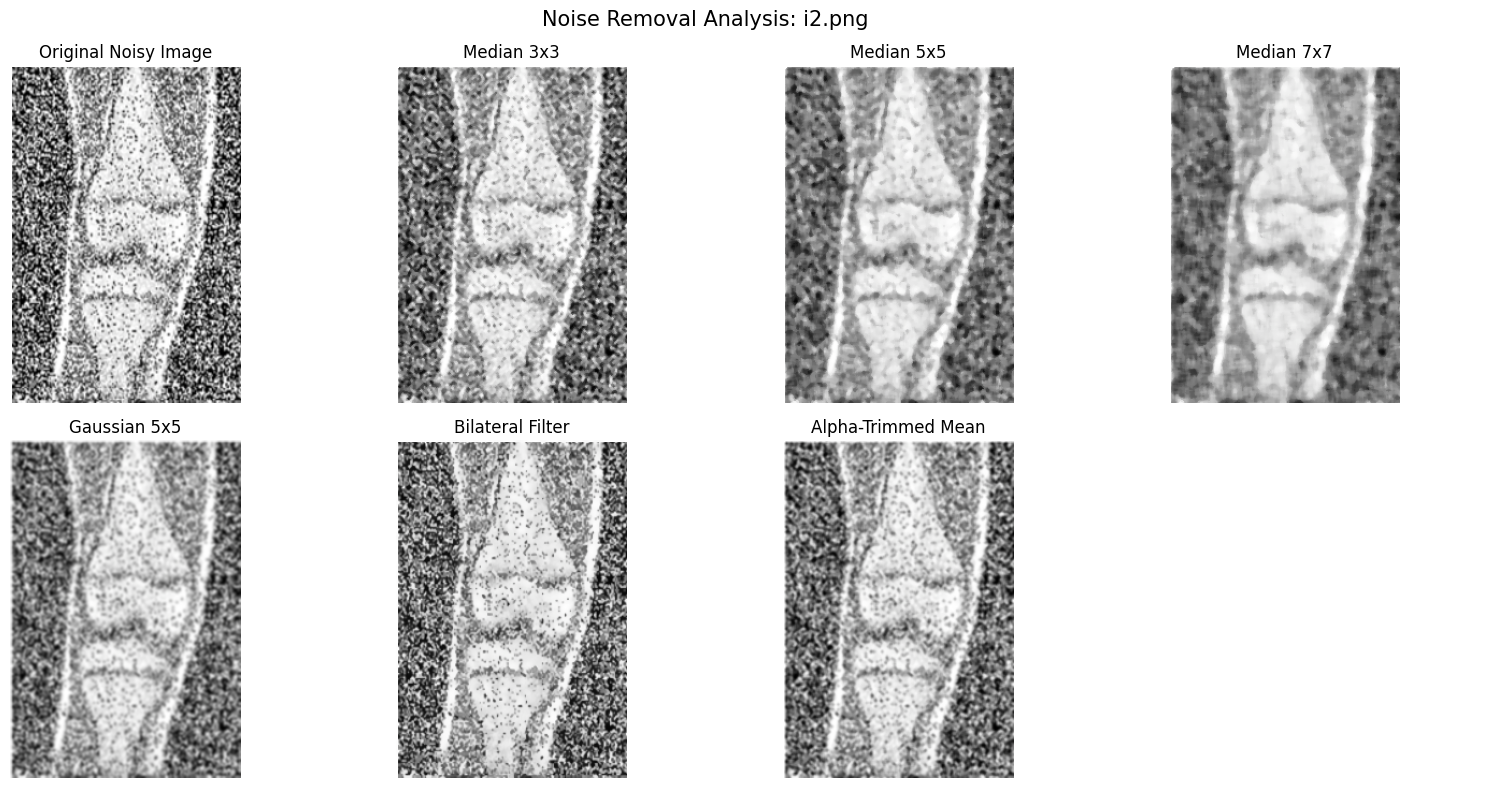

Processed image: i2.png
Results saved in: OPE7_Results\i2


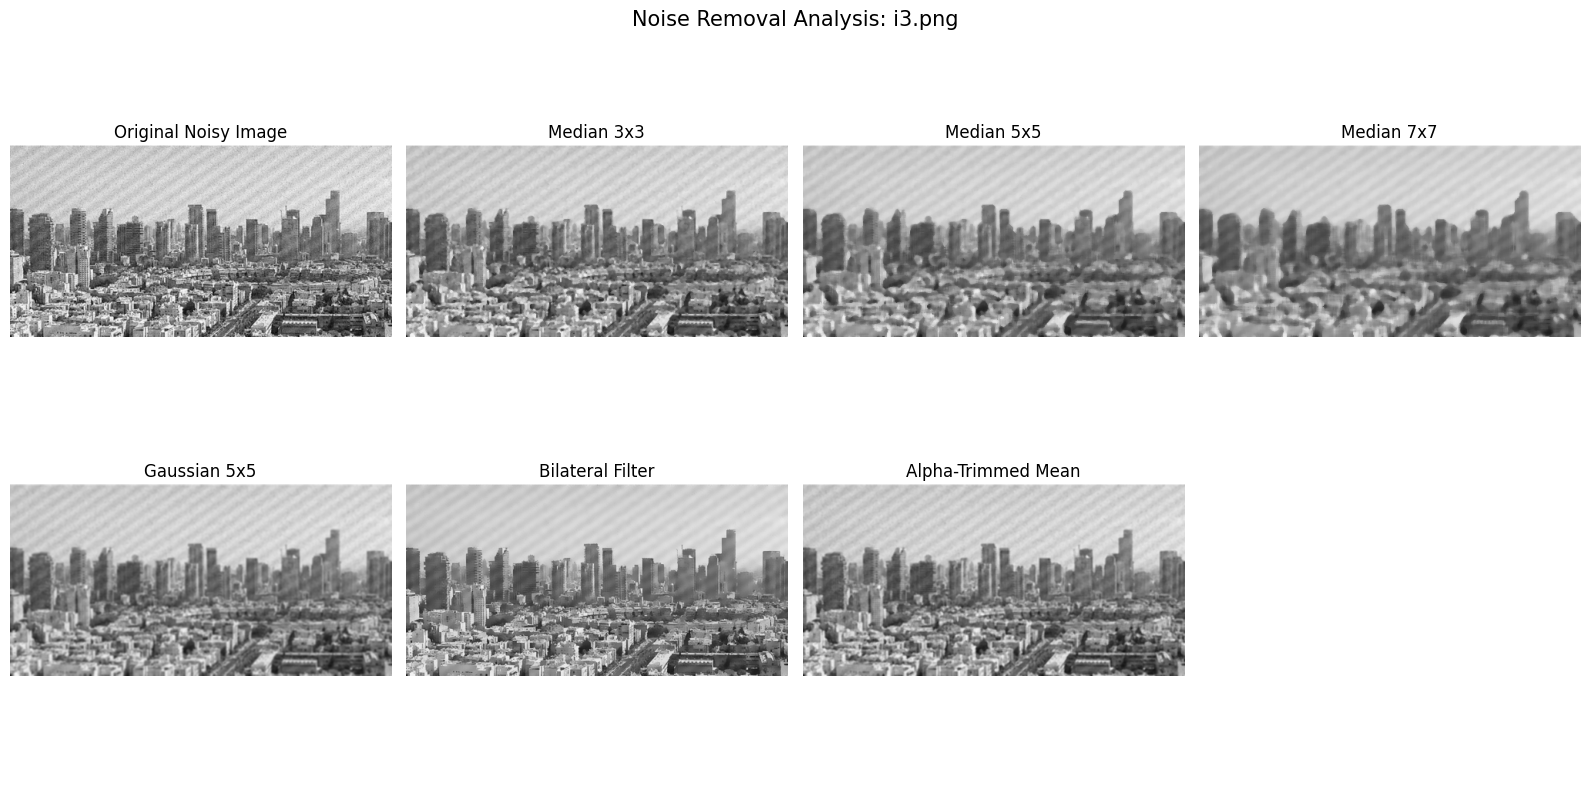

Processed image: i3.png
Results saved in: OPE7_Results\i3


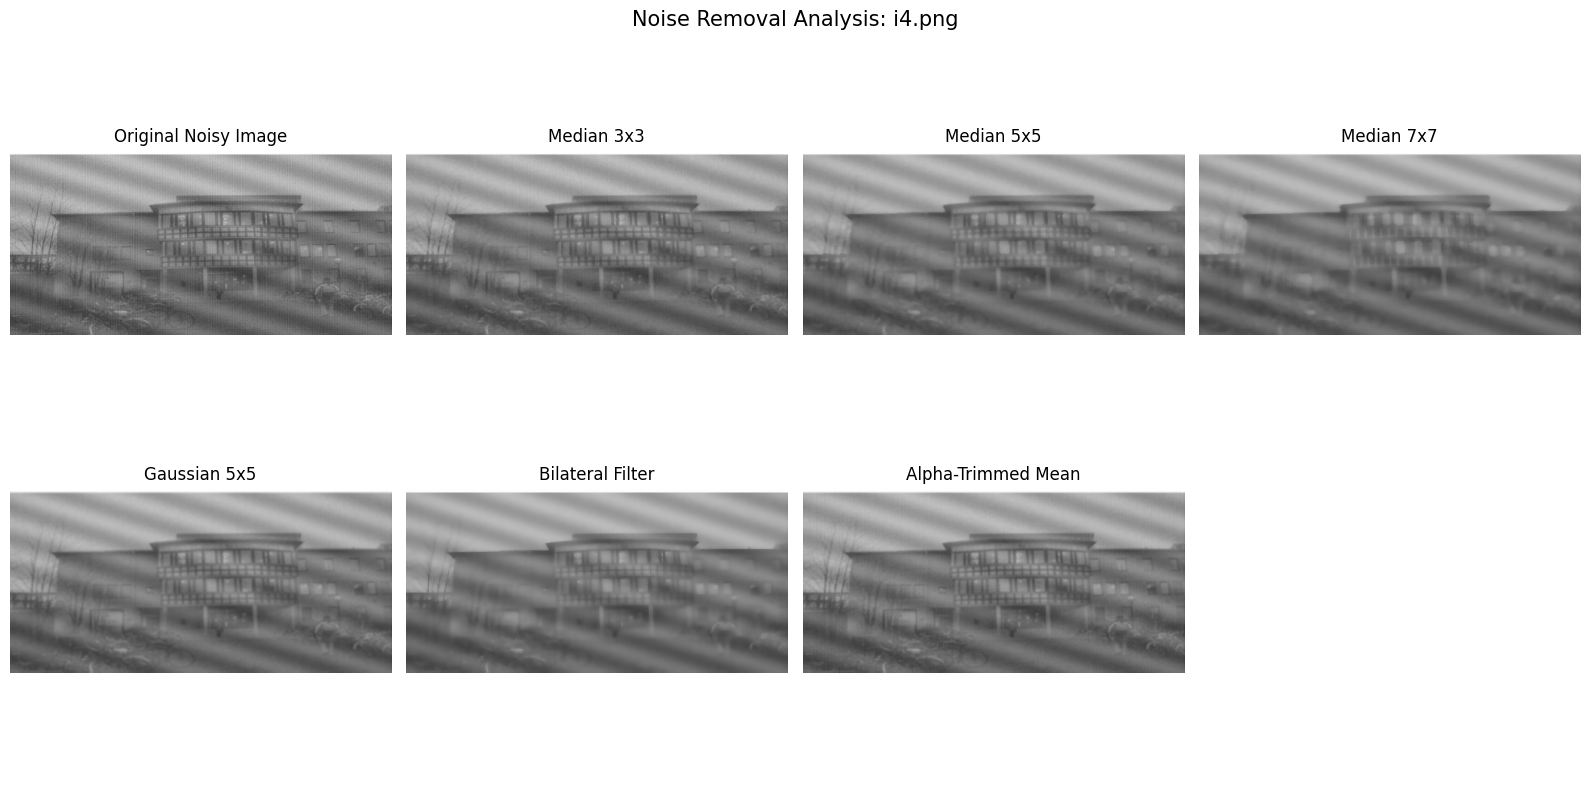

Processed image: i4.png
Results saved in: OPE7_Results\i4

All images processed successfully!


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import generic_filter
from skimage.metrics import structural_similarity
from skimage.metrics import peak_signal_noise_ratio

# Dataset folder
dataset_path = Path(".")

if not dataset_path.exists():
    raise FileNotFoundError("Create an OPE7 folder and add your noisy images.")

# Supported image formats
extensions = ["*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff"]
image_paths = []

for ext in extensions:
    image_paths.extend(dataset_path.glob(ext))

if not image_paths:
    raise FileNotFoundError("No images found inside the OPE7 folder.")

# Alpha-trimmed mean filter
def alpha_trimmed_filter(image, ksize=3, d=2):
    def trim_mean(values):
        values = np.sort(values)
        if d >= len(values):
            return np.mean(values)
        return np.mean(values[d // 2:len(values) - (d - d // 2)])

    if image.ndim == 2:
        return generic_filter(
            image.astype(np.float32),
            trim_mean,
            size=ksize,
            mode="reflect"
        ).clip(0, 255).astype(np.uint8)

    channels = [
        generic_filter(
            image[:, :, c].astype(np.float32),
            trim_mean,
            size=ksize,
            mode="reflect"
        )
        for c in range(image.shape[2])
    ]

    return np.stack(channels, axis=2).clip(0, 255).astype(np.uint8)


# Apply filters and compare results
for image_path in image_paths:

    image = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)

    if image is None:
        print(f"Could not read: {image_path}")
        continue

    # Convert OpenCV BGR to RGB for display
    if image.ndim == 3 and image.shape[2] == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    elif image.ndim == 3 and image.shape[2] == 4:
        image = cv2.cvtColor(image, cv2.COLOR_BGRA2RGB)

    # Convert unsupported formats to grayscale
    if image.ndim == 3 and image.shape[2] not in (3,):
        image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Median filters with different window sizes
    median_3 = cv2.medianBlur(image, 3)
    median_5 = cv2.medianBlur(image, 5)
    median_7 = cv2.medianBlur(image, 7)

    # Gaussian and bilateral filters
    gaussian = cv2.GaussianBlur(image, (5, 5), 0)
    bilateral = cv2.bilateralFilter(image, 9, 75, 75)

    # Alpha-trimmed mean filter
    alpha_trimmed = alpha_trimmed_filter(image, ksize=3, d=2)

    # Display results
    results = [
        ("Original Noisy Image", image),
        ("Median 3x3", median_3),
        ("Median 5x5", median_5),
        ("Median 7x7", median_7),
        ("Gaussian 5x5", gaussian),
        ("Bilateral Filter", bilateral),
        ("Alpha-Trimmed Mean", alpha_trimmed)
    ]

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for ax, (title, result) in zip(axes, results):
        if result.ndim == 2:
            ax.imshow(result, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(result)

        ax.set_title(title)
        ax.axis("off")

    axes[-1].axis("off")
    fig.suptitle(f"Noise Removal Analysis: {image_path.name}", fontsize=15)
    plt.tight_layout()
    plt.show()

    # Save filtered images
    output_dir = Path("OPE7_Results") / image_path.stem
    output_dir.mkdir(parents=True, exist_ok=True)

    filtered_images = {
        "median_3x3": median_3,
        "median_5x5": median_5,
        "median_7x7": median_7,
        "gaussian_5x5": gaussian,
        "bilateral": bilateral,
        "alpha_trimmed": alpha_trimmed
    }

    for name, result in filtered_images.items():
        save_image = result

        if result.ndim == 3:
            save_image = cv2.cvtColor(result, cv2.COLOR_RGB2BGR)

        cv2.imwrite(str(output_dir / f"{name}.png"), save_image)

    print(f"Processed image: {image_path.name}")
    print(f"Results saved in: {output_dir}")

print("\nAll images processed successfully!")